In [1]:
# Bloco 1: Carregamento dos dados

# Para iniciar o seu Jupyter Notebook (.ipynb) na tarefa de Classificação de Texto, o primeiro passo é carregar os dados para memória e separar os textos (perguntas) das respetivas classes (autor ou tema).
# Na Ficha Prática 3 (Representação e Classificação de texto com Scikit-Learn), a leitura de ficheiros é demonstrada no Exemplo 1.1 e Exemplo 2.1, utilizando a função nativa open() do Python para ler ficheiros linha a linha e armazenar os textos. Na aula teórica de Classificação de Texto (Slide 14), define-se que um classificador supervisionado precisa de um conjunto de documentos $d$ e das respetivas classes pré-definidas $c$. Na Ficha 3, este conceito é mapeado diretamente para a criação das variáveis lista_X (documentos) e lista_y (classes)
# Como o seu dataset do projeto não é um texto corrido genérico, mas sim um ficheiro onde as colunas estão separadas por tabulações, o código lecionado na Ficha 3 precisa de adaptações específicas (nomeadamente o uso de .split('\t') e a gestão do cabeçalho) para isolar a coluna da Pergunta e a coluna do Método (ou Tema)
def carrega_dados_tsv(ficheiro, index_texto=2, index_classe=3):
    """
    Baseado na função 'carrega_docs' da Ficha 3 (Exemplo 1.1 e 2.1).
    Lê o ficheiro e separa as colunas.
    """
    lista_X = [] # Armazena os documentos (perguntas) - de acordo com Ficha 3
    lista_y = [] # Armazena as classes (ex: HUM ou LLM) - de acordo com Ficha 3

    # A Ficha 3 utiliza open() e readlines() para ler o ficheiro
    with open(ficheiro, encoding='utf-8') as f:
        linhas = f.readlines()

    # [NÃO ESTÁ NAS FICHAS] Identificar e ignorar o cabeçalho. A Ficha 3 usa ficheiros .txt sem cabeçalho. O seu .tsv do projeto possui cabeçalho.
    if "Autor" in linhas[0]:
        linhas = linhas[1:] # Ignora a primeira linha

    for linha in linhas:
        # A Ficha 3 usa .strip() para limpar quebras de linha e espaços marginais na linha inteira
        linha = linha.strip()
        
        if len(linha) > 0:
            # [NÃO ESTÁ NAS FICHAS] O projeto exige divisão por tabulações
            colunas = linha.split('\t')
            
            # garante que a linha tem as 5 colunas esperadas só para dupla verificação
            if len(colunas) == 5:
                pergunta = colunas[index_texto]
                
                # PROBLEMA DETETADO: Aspas geradas pela exportação do TSV (ex: "Quem pintou os ""Painéis de São Vicente de Fora""?)
                # ^ -> Limpeza da pergunta
                pergunta = pergunta.strip() # Remove espaços vazios anómalos no início ou fim
                # Remove as aspas exteriores se existirem
                if pergunta.startswith('"') and pergunta.endswith('"'):
                    pergunta = pergunta[1:-1]
                    
                # Reverte as aspas duplas interiores para aspas normais
                pergunta = pergunta.replace('""', '"')

                # Guarda a pergunta limpa e a classe nas respetivas listas
                lista_X.append(pergunta)
                lista_y.append(colunas[index_classe])
                
    return lista_X, lista_y

#remover os [] dos temas

#Quando o código lê uma linha do seu ficheiro .tsv e a divide pelas tabulações (com o comando .split('\t')), cria uma lista onde cada coluna ocupa uma posição específica
#O mapeamento dos índices para o cabeçalho do seu dataset é o seguinte:
    # 0: Autor
    # 1: Tema
    # 2: Pergunta
    # 3: Método (HUM ou LLM)
    # 4: Resposta

# Carregar os dados de treino e teste
# Índices: 2 = Pergunta, 3 = Método (HUM/LLM). 
# Se optar por classificar o Tema na Meta 2, mude o index_classe para 1.
                                #QUESTÃO: devemos incluir a resposta ou só a pergunta? por enquanto está só a pergunta
X_train, y_train = carrega_dados_tsv('dataset_PLN_train.tsv', index_texto=2, index_classe=1)
X_test, y_test = carrega_dados_tsv('dataset_PLN_test.tsv', index_texto=2, index_classe=1)
    #Num problema de classificação de texto, o modelo precisa de um texto de entrada (o $X$). Como o objetivo da Meta 2 é classificar as perguntas criadas na Meta 1, dizemos à função para extrair o texto que se encontra na posição 2 da lista (index_texto=2
    #O modelo também precisa da etiqueta correta para aprender (o $y$). O guião do projeto estipula que a tarefa de Classificação de Texto na Meta 2 tem duas opções à escolha do grupo: classificar as perguntas de acordo com o seu autor (HUM ou LLM)/de acordo com o seu tema. Por isso, se index_classe=3, guardamos autor (HUM/LLM). Se index_classe=1 guardamos o tema.

# Check
print(f"Total de perguntas de treino: {len(X_train)}")
print(f"Total de perguntas de teste: {len(X_test)}")

print("\nAmostra do Treino (Classe -> Documento):")
#Em Processamento de Linguagem Natural (PLN), "Documento" é o termo técnico padrão utilizado para descrever a unidade básica de texto que está a ser processada ou classificada por um algoritmo. No contexto do seu projeto, um "documento" não é um ficheiro completo (como um Word ou PDF), mas sim a Pergunta

for i in range(30):
    print(f"{y_train[i]} \t\t {X_train[i]}")
print("\nAmostra do Teste (Classe -> Documento):")
for i in range(30):
    print(f"{y_test[i]} \t\t {X_test[i]}")

Total de perguntas de treino: 342
Total de perguntas de teste: 86

Amostra do Treino (Classe -> Documento):
Ténis 		 Em que país decorre o torneio de Wimbledon?
Teologia e Filosofia 		 Qual é o princípio fundamental da ética kantiana?
Geografia de Portugal 		 Qual é o maior rio que desagua em Portugal?
Tradições e festas 		 Como se chama a missa celebrada à meia-noite do dia 25 de dezembro, em Portugal?
Teologia e Filosofia 		 Qual a diferença entre a antropologia e pneumatologia?
História de Portugal 		 Quem criou o Conselho de Estado após a Revolução de Abril?
Mitologia Grega 		 Quantos deuses principais compunham o panteão olímpico?
F1 		 Em que ano Max Verstappen venceu o seu primeiro título mundial?
Cinema 		 Em que década começou a produção regular da série "Os Simpsons"?
Basquetebol 		 Que objeto serviu de cestos nos primeiros jogos de basquetebol em 1891?
Videojogos 		 Que estúdio é responsável pela criação da famosa franquia "Grand Theft Auto" (GTA)?
Pintura 		 Em que museu de

In [2]:
from collections import Counter

print("Contagem de perguntas no treino de cada tema:")
# O Counter analisa a lista e cria um dicionário com a frequência de cada tema
contagem_treino = Counter(y_train)
for tema, quantidade in contagem_treino.items():
    print(f"- {tema}: {quantidade}")

print("\nContagem de perguntas no teste de cada tema:")
contagem_teste = Counter(y_test)
for tema, quantidade in contagem_teste.items():
    print(f"- {tema}: {quantidade}")

Contagem de perguntas no treino de cada tema:
- Ténis: 16
- Teologia e Filosofia: 16
- Geografia de Portugal: 16
- Tradições e festas: 16
- História de Portugal: 16
- Mitologia Grega: 16
- F1: 13
- Cinema: 16
- Basquetebol: 16
- Videojogos: 16
- Pintura: 15
- Cibersegurança: 16
- Gastronomia: 16
- Corpo Humano e Anatomia: 16
- Vinhos: 16
- Motorizações e Energia Automóvel: 16
- Futebol: 14
- Filosofia: 16
- Países: 16
- Jogos Olímpicos: 14
- Animais: 14
- Tradições Académicas de Coimbra: 16

Contagem de perguntas no teste de cada tema:
- Videojogos: 4
- Pintura: 4
- Basquetebol: 4
- Cinema: 4
- História de Portugal: 4
- Cibersegurança: 4
- Teologia e Filosofia: 4
- Geografia de Portugal: 4
- Motorizações e Energia Automóvel: 4
- Futebol: 3
- F1: 3
- Tradições Académicas de Coimbra: 4
- Vinhos: 4
- Jogos Olímpicos: 4
- Filosofia: 4
- Corpo Humano e Anatomia: 4
- Tradições e festas: 4
- Mitologia Grega: 4
- Países: 4
- Animais: 4
- Ténis: 4
- Gastronomia: 4


---

In [3]:
# Bloco 2: Representação de Texto (Vetorização)

#Os algoritmos não conseguem processar texto bruto; as palavras têm de ser convertidas em matrizes numéricas (o modelo Bag-of-Words). Conforme lecionado na Ficha Prática 3, a biblioteca scikit-learn fornece duas ferramentas principais para isto:
    #CountVectorizer: Conta simplesmente as frequências absolutas das palavras dentro de cada documento (não compara diferentes documentos), dando pontuação alta a palavras que se repetem muitas vezes
    #TfidfVectorizer: Pondera a importância das palavras usando TF-IDF (Term Frequency-Inverse Document Frequency), reduzindo o peso de palavras muito comuns (como "que", "de", "o") e destacando termos específicos do documento.
            #^ -> o calculo é dividido em duas partes:
            # 1) TF(Frequencia do Termo): Mede o quão frequente uma palavra é dentro de um único documento, sendo que quanto mais aparecer naquele documento, maior é o seu peso TF
            # 2) IDF (Inverse Document Frequency / Frequência Inversa do Documento): Mede o quão rara uma palavra é ao longo de todos os documentos da sua base de dados (corpus),ou seja, palavras muito comuns (ex: que) ganham um peso IDF baixo.
            # Resultado = TF*IDF. Uma palavra só terá uma pontuação alta se for frequente no documento atual, mas rara nos outros documentos. Isso ajuda o modelo de Machine Learning a entender o que realmente torna aquele texto único
#Um aspeto crítico ensinado no Exemplo 2.3 da Ficha Prática 3: o vetorizador deve "aprender" o vocabulário exclusivamente com os dados de treino utilizando a função fit_transform. Os dados de teste, por representarem o "mundo real" desconhecido, só podem ser transformados com base nesse vocabulário prévio, utilizando apenas a função transform

#Por que o TfidfVectorizer costuma ser a melhor escolha: Em perguntas curtas, se o utilizador usa uma palavra rara como "rio" (geografia) ou "malware" (cibersegurança), essa palavra é o indicador máximo do tema. O TF-IDF vai identificar que essa palavra é rara no corpus e vai dar um peso enorme a ela. Palavras comuns como "como", "onde", "posso" terão o peso esmagado.



# Baseado na Ficha Prática 3, secção 1.2 (Exemplos 1.2 a 1.5) e secção 2.2 (Exemplo 2.3).
# Importação dos vetorizadores do scikit-learn
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# A Ficha 3 (Exemplo 1.4 e 1.5) recomenda o uso de opções como ngram_range ou stopwords.
vetorizador = TfidfVectorizer(
    ngram_range=(1, 2), # Define o tamanho das sequências de palavras (n-gramas) que o modelo vai extrair e considerar como características (features) independentes. O valor (1, 2) instrui o vetorizador a mapear tanto unigramas (palavras isoladas) como bigramas (pares de palavras consecutivas). Numa frase como "inteligência artificial avança", o modelo cria as características "inteligência", "artificial", "avança", mas também "inteligência artificial" e "artificial avança". Extrair n-gramas preserva o contexto imediato das palavras e permite ao modelo captar expressões multi-palavra cujo significado se perde quando as palavras são separadas
    strip_accents='unicode', # Remove acentuação antes de processar. Esta normalização garante que as palavras são agrupadas corretamente, independentemente de erros ortográficos ou variações na digitação. Sem isto, o vetorizador trataria "câmara" e "camara" como duas características totalmente distintas, dividindo o peso da palavra em duas colunas separadas na matriz
    min_df=2 # Minimum Document Frequency: Este parâmetro define um valor mínimo para o número de documentos (neste caso, perguntas) em que uma característica tem de ocorrer para ser guardada no vocabulário do modelo. Ao definir min_df=2, obriga a que uma palavra ou bigrama apareça em pelo menos duas perguntas diferentes. Termos que ocorrem num único documento têm baixo poder de discriminação e limitam a capacidade do classificador generalizar, pelo que são descartados para reduzir o ruído e o tamanho da matriz
        #vamos testar 2 por agora e ver o que sai daqui
)

# O vetorizador aprende o vocabulário apenas com o Treino e transforma os dados (Exemplo 2.3 da Ficha 3)
X_train_vec = vetorizador.fit_transform(X_train)

# O Teste é APENAS transformado (não aprende vocabulário novo), usando o conhecimento do Treino (Exemplo 2.3 da Ficha 3)
X_test_vec = vetorizador.transform(X_test)

# Validação do formato das matrizes esparsas resultantes
print(f"Formato da matriz de Treino: {X_train_vec.shape}")
print(f"Formato da matriz de Teste: {X_test_vec.shape}")
    #^mostram (nºlinhas=perguntas, nºcolunas=número de palavras/features únicas que cumprem os parâmetros definidos no vetorizador)

Formato da matriz de Treino: (342, 644)
Formato da matriz de Teste: (86, 644)


---

In [4]:
# Bloco 4: Modelação e Avaliação

# Modelos mencionados nas aulas:
    # Modelos Clássicos de Classificação
        # º Naive Bayes (MultinomialNB) - Rápido e desenhado nativamente para lidar com as contagens puras do modelo Bag-of-Words através do CountVectorizer. Serve como um baseline (modelo de referência inicial) para a classificação de temas, agrupando palavras frequentes num conjunto de dados pequeno.
                                        # MAS Assume que as palavras são independentes entre si e ignora completamente a estrutura da frase. Teria dificuldades em classificar o Autor (HUM vs LLM), pois um LLM não usa apenas palavras diferentes mas sim uma estrutura sintática que o Naive Bayes ignora. Sofre com palavras desconhecidas no teste (causa divisões por 0) mas isso resolve-se com Laplace smoothing.
        # º Regressão Logística         - Sendo um modelo discriminativo, funciona de forma excelente com o TfidfVectorizer, atribuindo pesos matemáticos precisos às características (palavras raras). Pode ser efetivo a desenhar as fronteiras matemáticas que separam os 22 temas
                                        # MAS ode sofrer de overfitting (memorizar o treino em vez de generalizar) num dataset com poucas dezenas de perguntas por tema, caso os pesos não sejam bem regularizados
        # º Support Vector Machines (SVC) - Notável capacidade para lidar com espaços de alta dimensionalidade (como a sua matriz de 644 colunas gerada para poucas linhas de texto). É um dos modelos mais fortes para capturar padrões complexos, sendo uma excelente aposta para distinguir o estilo HUM vs LLM
                                          # MAS Mais lento de treinar e prever do que o Naive Bayes. Os hiperparâmetros (como o tipo de kernel ou margem) exigem afinação cuidadosa para não falhar nas previsões
        # º kNN                         - Intuitivo, classificando uma pergunta de teste com base na classe das perguntas de treino matematicamente mais "próximas"
                                        # MAS É devastado pela "maldição da dimensionalidade". Com 644 colunas e vetores esparsos (muitos zeros), a medição de distância entre as perguntas pode tornar-se ineficaz. Possivelmente vai ter um desempenho fraco neste projeto
        # º RandomForest                - Robusto contra o ruído (como erros ortográficos humanos), pois combina a decisão de várias árvores independentes (ensemble)
                                        # MAS O modelo tende a ser pesado e não costuma superar o SVC ou a Regressão Logística em tarefas de texto simples usando TF-IDF

# Vamos usar regressão, SVC e randomforest


In [5]:
# Baseado na Ficha Prática 3, secção 2.2 (Exemplos 2.4 e 2.5) e secção 2.3 (Exercício 2.2).
# A Regressão Logística foi abordada nas aulas teóricas como um método discriminativo.
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. INICIALIZAR O MODELO
# max_iter=1000 garante que o algoritmo tem tempo para encontrar a solução matemática
# random_state=42 garante que os resultados são reproduzíveis sempre que correr o código
modelo_lr = LogisticRegression(max_iter=1000, random_state=42)

# 2. TREINAR O MODELO (Fase de Aprendizagem)
# O modelo recebe a matriz matemática de treino e as etiquetas (temas) corretas
modelo_lr.fit(X_train_vec, y_train)

# 3. FAZER PREVISÕES (Fase de Teste)
# O modelo tenta adivinhar o tema das perguntas de teste sem conhecer as respostas
previsoes_lr = modelo_lr.predict(X_test_vec)

# 4. AVALIAÇÃO DOS RESULTADOS
print("=== AVALIAÇÃO: REGRESSÃO LOGÍSTICA ===")

# O classification_report calcula a Precisão, Abrangência (Recall) e F1-score para cada tema
# As aulas teóricas destacam a importância do F1-score como média harmónica da Precisão e Abrangência
relatorio = metrics.classification_report(y_test, previsoes_lr, target_names=set(y_train))
print(relatorio)

=== AVALIAÇÃO: REGRESSÃO LOGÍSTICA ===
                                  precision    recall  f1-score   support

Motorizações e Energia Automóvel       1.00      0.75      0.86         4
                          Cinema       1.00      0.50      0.67         4
         Corpo Humano e Anatomia       0.50      0.75      0.60         4
                     Gastronomia       0.50      0.75      0.60         4
                      Videojogos       0.75      0.75      0.75         4
                         Futebol       1.00      1.00      1.00         3
                     Basquetebol       1.00      0.50      0.67         4
                       Filosofia       0.29      0.67      0.40         3
                  Cibersegurança       0.75      0.75      0.75         4
                         Animais       0.50      0.50      0.50         4
                           Ténis       0.60      0.75      0.67         4
              Tradições e festas       1.00      1.00      1.00         


Matriz de Confusão (Heatmap):


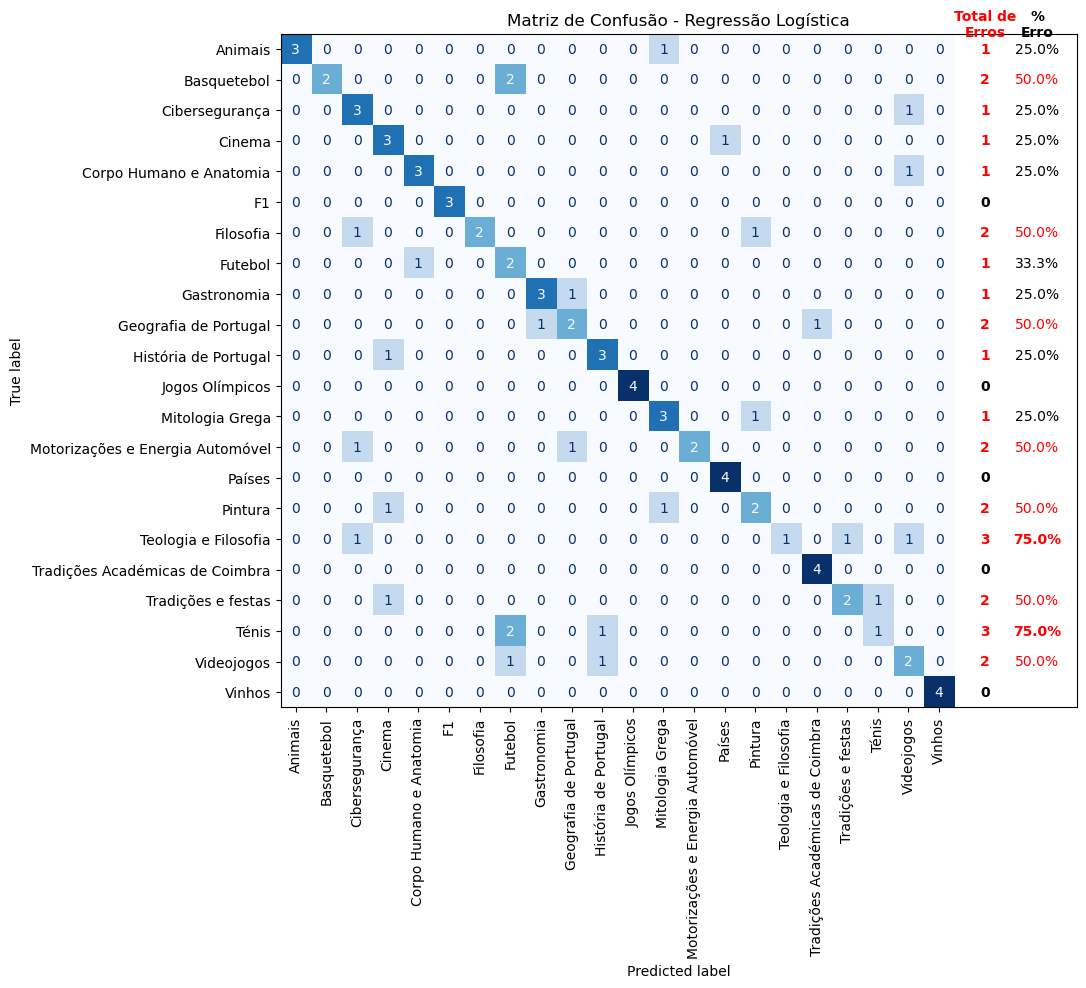

In [6]:
#                                               visualização gerada pelo gemini <-----------------------------------------
# foi pedido um heatmap labelxprevisão com 2 colunas extras: nºerros por cada tema + percentagem. foi necessário pedir alguns ajustes visuais que não são relevantes a serem explicitados.

print("\nMatriz de Confusão (Heatmap):")

# Gera o heatmap diretamente a partir das previsões que o modelo acabou de fazer
grafico = ConfusionMatrixDisplay.from_predictions(
    y_test, 
    previsoes_lr,
    cmap='Blues',               # Usa tons de azul (facilita a leitura do contraste)
    xticks_rotation='vertical', # Roda os nomes dos temas no eixo X a 90 graus
    colorbar=False              # Oculta a barra de escala lateral para maximizar o espaço
)

# 1. Aumentar a largura para acomodar as novas colunas
grafico.figure_.set_size_inches(14, 10)

# 2. Obter a matriz numérica e o número de classes
cm = grafico.confusion_matrix
num_classes = len(grafico.display_labels)

# 3. Calcular totais, erros absolutos e percentagens
total_por_tema = cm.sum(axis=1)
erros_por_tema = total_por_tema - cm.diagonal()

# 4. Desenhar as colunas no gráfico
ax = grafico.ax_
posicao_x_erros = num_classes + 0.5 # Posição da 1ª coluna extra
posicao_x_perc = num_classes + 2.2  # AFASTADO: Aumentado de 1.5 para 2.2 para não sobrepor

# Adicionar os cabeçalhos
ax.text(posicao_x_erros, -0.8, "Total de\nErros", ha='center', va='center', fontweight='bold', color='red', fontsize=10)
# CORRIGIDO: Cor fixa em 'black'
ax.text(posicao_x_perc, -0.8, "%\nErro", ha='center', va='center', fontweight='bold', color='black', fontsize=10)

# Adicionar os valores linha a linha
for i in range(num_classes):
    # A cor vermelha aplica-se apenas ao valor absoluto se houver erros
    cor_erro = 'red' if erros_por_tema[i] > 0 else 'black'
    
    # Imprime o número absoluto de erros
    ax.text(posicao_x_erros, i, str(erros_por_tema[i]), ha='center', va='center', fontweight='bold', color=cor_erro)
    
    # Calcula e imprime a percentagem formatada a 1 casa decimal (ex: 25.0%)
    # CORRIGIDO: Cor fixada em 'black' independentemente de haver erro ou não
    perc = (erros_por_tema[i] / total_por_tema[i]) * 100 if total_por_tema[i] > 0 else 0
    if perc>0:
        if perc>=50 and perc<75:
            ax.text(posicao_x_perc, i, f"{perc:.1f}%", ha='center', va='center', color='red')
        elif perc>=75:
            ax.text(posicao_x_perc, i, f"{perc:.1f}%", ha='center', va='center', fontweight='bold', color='red')
        else:
            ax.text(posicao_x_perc, i, f"{perc:.1f}%", ha='center', va='center', color='black')


# 5. Expandir os limites do eixo X para acomodar a segunda coluna (aumentado para + 3.5)
ax.set_xlim(-0.5, num_classes + 3.5)

plt.title("Matriz de Confusão - Regressão Logística")
plt.tight_layout() # Garante que os rótulos não ficam cortados nas margens
plt.show()

In [7]:
print("\n=== PERGUNTAS CLASSIFICADAS INCORRETAMENTE ===")

contador_erros = 0

# Percorrer todas as instâncias do conjunto de teste
for i in range(len(y_test)):
    # Se a etiqueta real for diferente da etiqueta prevista pelo modelo
    if y_test[i] != previsoes_lr[i]:
        contador_erros += 1
        print(f"Pergunta: {X_test[i]}")
        print(f"Real: [{y_test[i]}]  |  Previsão do Modelo: [{previsoes_lr[i]}]")
        print("-" * 60)

print(f"\nTotal de erros cometidos: {contador_erros} em {len(y_test)} perguntas de teste.")


=== PERGUNTAS CLASSIFICADAS INCORRETAMENTE ===
Pergunta: Qual foi o nome da equipa que venceu o primeiro EuroBasket?
Real: [Basquetebol]  |  Previsão do Modelo: [Futebol]
------------------------------------------------------------
Pergunta: Que significado tem o termo "dogma" no contexto teológico?
Real: [Teologia e Filosofia]  |  Previsão do Modelo: [Cibersegurança]
------------------------------------------------------------
Pergunta: Quantos habitantes tem o distrito de Coimbra?
Real: [Geografia de Portugal]  |  Previsão do Modelo: [Tradições Académicas de Coimbra]
------------------------------------------------------------
Pergunta: Qual foi a atriz com maior número de nomeações ao Óscar até à data de 2023?
Real: [Cinema]  |  Previsão do Modelo: [Países]
------------------------------------------------------------
Pergunta: O que são  sacramentos?
Real: [Teologia e Filosofia]  |  Previsão do Modelo: [Videojogos]
------------------------------------------------------------
Pergun

> GEMINI

A análise destes destes 28 erros (taxa de acerto de cerca de 67% num problema complexo de 22 classes) demonstra as limitações teóricas do modelo *Bag-of-Words* e do TF-IDF, que representam os textos apenas com base nas frequências das palavras, ignorando o seu significado e a ordem na frase.

Aqui estão os três grandes padrões de erro que o seu modelo cometeu, e que pode dissecar diretamente no seu relatório:

**1. O Domínio de Vocabulário Partilhado (O "Buraco Negro" do Futebol)**
Repare como o modelo classificou várias perguntas de Ténis, Basquetebol e Videojogos como "Futebol":

* *Qual foi o nome da **equipa** que **venceu** o primeiro EuroBasket?* (Previu Futebol)
* *Qual **jogador conquistou** o US Open em 2022?* (Previu Futebol)
* *Quem é o tenista com mais **títulos**...?* (Previu Futebol)

**Porquê?** Palavras como "equipa", "venceu", "jogador" e "títulos" devem ter aparecido esmagadoramente nas perguntas de treino sobre Futebol. Como o TF-IDF baseia-se em frequências, o modelo associou matematicamente esses termos ao Futebol. Quando a palavra "EuroBasket" ou "US Open" apareceu no teste (talvez filtrada pelo `min_df=2` ou desconhecida), o modelo agarrou-se aos verbos e nomes genéricos de desporto para tomar a decisão.

**2. Ambiguidade Lexical (A armadilha das palavras-chave cruzadas)**
O modelo tropeçou em palavras que pertencem fortemente a um tema no conjunto de treino, mas que no teste apareceram noutro contexto. Este é um problema clássico de ambiguidade que os algoritmos de contagem de palavras não conseguem resolver:

* *Quantos habitantes tem o distrito de **Coimbra**?* (Geografia -> Previu Tradições Académicas de Coimbra)
* *...queijo **Serra da Estrela**, no **Centro** de **Portugal**?* (Gastronomia -> Previu Geografia de Portugal)
* *...consumido em **Portugal** em 2024?* (Motorizações -> Previu Geografia de Portugal)

**Porquê?** A Regressão Logística aprendeu que a palavra "Coimbra" é o maior preditor para "Tradições Académicas", e "Portugal/Centro" para "Geografia". O algoritmo não compreende o conceito de "habitantes" ou "queijo", apenas soma os pesos das características. Se o peso da palavra "Coimbra" for muito alto, esmaga o resto da frase.

**3. Ambiguidade Temática Genuína**
Algumas perguntas do seu dataset pertencem efetivamente a duas categorias, provando que a taxonomia não é estanque:

* *Que **filme** de **animação da Pixar**, lançado em 2017, retrata a tradição do Dia de los Muertos no México?* (Tradições e festas -> Previu Cinema)

**Porquê?** O modelo não errou por falta de capacidade matemática, mas porque a pergunta é um híbrido. A presença de "filme", "animação" e "Pixar" ativou imediatamente os pesos pesados da classe Cinema, ofuscando a referência à tradição.

**Como usar isto a seu favor?**
O guião do projeto sugere explicitamente que a secção de discussão dos resultados no relatório inclua, idealmente, uma "análise de erros". Pode copiar 3 ou 4 destes exemplos para o documento e explicar que, como o classificador e o `TfidfVectorizer` processam as perguntas desprovidas da sua semântica e contexto estrutural, é natural que junte temas com léxico sobreposto (como os desportos) ou que seja enganado por palavras-chave com pesos enviesados (como "Coimbra" ou "Portugal").

---

In [8]:
from sklearn.svm import SVC

# 1. INICIALIZAR O MODELO
# kernel='linear' é habitualmente a melhor escolha para classificação de texto com TF-IDF
modelo_svc = SVC(kernel='linear', random_state=42)

# 2. TREINAR O MODELO
modelo_svc.fit(X_train_vec, y_train)

# 3. FAZER PREVISÕES
previsoes_svc = modelo_svc.predict(X_test_vec)

# 4. AVALIAÇÃO DOS RESULTADOS
print("=== AVALIAÇÃO: SUPPORT VECTOR MACHINES (SVC) ===")
relatorio_svc = metrics.classification_report(y_test, previsoes_svc, target_names=set(y_train))
print(relatorio_svc)

=== AVALIAÇÃO: SUPPORT VECTOR MACHINES (SVC) ===
                                  precision    recall  f1-score   support

Motorizações e Energia Automóvel       0.75      0.75      0.75         4
                          Cinema       1.00      0.50      0.67         4
         Corpo Humano e Anatomia       1.00      0.50      0.67         4
                     Gastronomia       0.57      1.00      0.73         4
                      Videojogos       0.75      0.75      0.75         4
                         Futebol       1.00      1.00      1.00         3
                     Basquetebol       0.75      0.75      0.75         4
                       Filosofia       0.25      0.67      0.36         3
                  Cibersegurança       0.67      1.00      0.80         4
                         Animais       1.00      0.50      0.67         4
                           Ténis       0.38      0.75      0.50         4
              Tradições e festas       1.00      0.75      0.8


Matriz de Confusão (Heatmap):


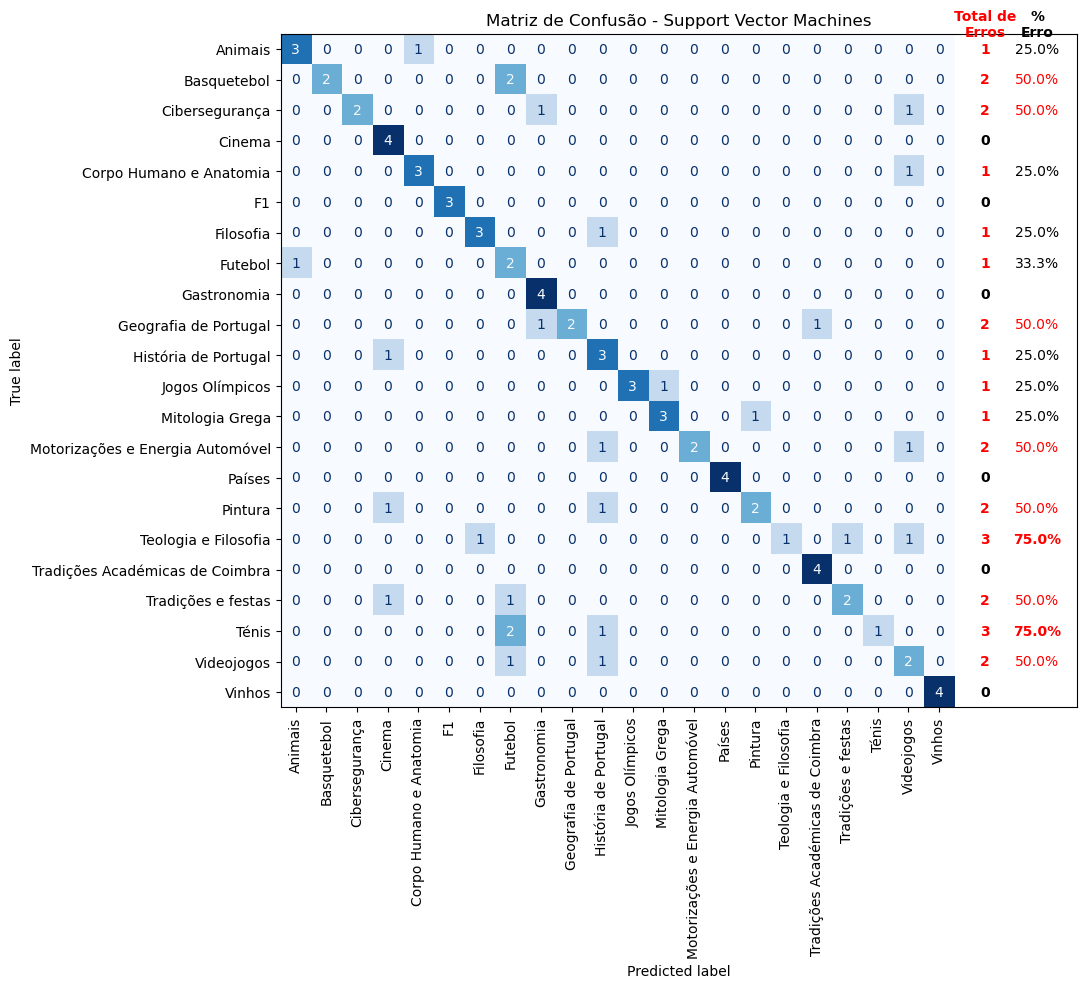

In [9]:
#                                               visualização gerada pelo gemini <-----------------------------------------
# foi pedido um heatmap labelxprevisão com 2 colunas extras: nºerros por cada tema + percentagem. foi necessário pedir alguns ajustes visuais que não são relevantes a serem explicitados.

print("\nMatriz de Confusão (Heatmap):")

# Gera o heatmap diretamente a partir das previsões que o modelo acabou de fazer
grafico = ConfusionMatrixDisplay.from_predictions(
    y_test, 
    previsoes_svc,
    cmap='Blues',               # Usa tons de azul (facilita a leitura do contraste)
    xticks_rotation='vertical', # Roda os nomes dos temas no eixo X a 90 graus
    colorbar=False              # Oculta a barra de escala lateral para maximizar o espaço
)

# 1. Aumentar a largura para acomodar as novas colunas
grafico.figure_.set_size_inches(14, 10)

# 2. Obter a matriz numérica e o número de classes
cm = grafico.confusion_matrix
num_classes = len(grafico.display_labels)

# 3. Calcular totais, erros absolutos e percentagens
total_por_tema = cm.sum(axis=1)
erros_por_tema = total_por_tema - cm.diagonal()

# 4. Desenhar as colunas no gráfico
ax = grafico.ax_
posicao_x_erros = num_classes + 0.5 # Posição da 1ª coluna extra
posicao_x_perc = num_classes + 2.2  # AFASTADO: Aumentado de 1.5 para 2.2 para não sobrepor

# Adicionar os cabeçalhos
ax.text(posicao_x_erros, -0.8, "Total de\nErros", ha='center', va='center', fontweight='bold', color='red', fontsize=10)
# CORRIGIDO: Cor fixa em 'black'
ax.text(posicao_x_perc, -0.8, "%\nErro", ha='center', va='center', fontweight='bold', color='black', fontsize=10)

# Adicionar os valores linha a linha
for i in range(num_classes):
    # A cor vermelha aplica-se apenas ao valor absoluto se houver erros
    cor_erro = 'red' if erros_por_tema[i] > 0 else 'black'
    
    # Imprime o número absoluto de erros
    ax.text(posicao_x_erros, i, str(erros_por_tema[i]), ha='center', va='center', fontweight='bold', color=cor_erro)
    
    # Calcula e imprime a percentagem formatada a 1 casa decimal (ex: 25.0%)
    # CORRIGIDO: Cor fixada em 'black' independentemente de haver erro ou não
    perc = (erros_por_tema[i] / total_por_tema[i]) * 100 if total_por_tema[i] > 0 else 0
    if perc>0:
        if perc>=50 and perc<75:
            ax.text(posicao_x_perc, i, f"{perc:.1f}%", ha='center', va='center', color='red')
        elif perc>=75:
            ax.text(posicao_x_perc, i, f"{perc:.1f}%", ha='center', va='center', fontweight='bold', color='red')
        else:
            ax.text(posicao_x_perc, i, f"{perc:.1f}%", ha='center', va='center', color='black')


# 5. Expandir os limites do eixo X para acomodar a segunda coluna (aumentado para + 3.5)
ax.set_xlim(-0.5, num_classes + 3.5)

plt.title("Matriz de Confusão - Support Vector Machines")
plt.tight_layout() # Garante que os rótulos não ficam cortados nas margens
plt.show()

In [10]:
print("\n=== PERGUNTAS CLASSIFICADAS INCORRETAMENTE ===")

contador_erros = 0

# Percorrer todas as instâncias do conjunto de teste
for i in range(len(y_test)):
    # Se a etiqueta real for diferente da etiqueta prevista pelo modelo
    if y_test[i] != previsoes_svc[i]:
        contador_erros += 1
        print(f"Pergunta: {X_test[i]}")
        print(f"Real: [{y_test[i]}]  |  Previsão do Modelo: [{previsoes_svc[i]}]")
        print("-" * 60)

print(f"\nTotal de erros cometidos: {contador_erros} em {len(y_test)} perguntas de teste.")


=== PERGUNTAS CLASSIFICADAS INCORRETAMENTE ===
Pergunta: Qual foi o nome da equipa que venceu o primeiro EuroBasket?
Real: [Basquetebol]  |  Previsão do Modelo: [Futebol]
------------------------------------------------------------
Pergunta: Que técnica consiste em introduzir instruções adversariais no texto de entrada de um LLM para forçá-lo a ignorar restrições?
Real: [Cibersegurança]  |  Previsão do Modelo: [Gastronomia]
------------------------------------------------------------
Pergunta: Que significado tem o termo "dogma" no contexto teológico?
Real: [Teologia e Filosofia]  |  Previsão do Modelo: [Filosofia]
------------------------------------------------------------
Pergunta: Quantos habitantes tem o distrito de Coimbra?
Real: [Geografia de Portugal]  |  Previsão do Modelo: [Tradições Académicas de Coimbra]
------------------------------------------------------------
Pergunta: O que são  sacramentos?
Real: [Teologia e Filosofia]  |  Previsão do Modelo: [Videojogos]
----------

> GEMINI

A análise detalhada aos falsos positivos do SVC, cruzada com a constatação de que termos críticos não sobreviveram ao treino, permite estruturar a secção de discussão de resultados do seu relatório em três hipóteses centrais e fundamentadas.

**O Efeito do Vetor Nulo e a Poda por Frequência**
A restrição do `min_df=2` conjugada com a ausência de lematização (o modelo não sabe que "coração" e "corações" são a mesma palavra) eliminou preditores do vocabulário. Em perguntas curtas e específicas como *"O coração humano é dividido (...)?"* ou *"O que são sacramentos?"* as palavras-chave (neste caso coração / coração humano ou sacramentos) foram descartadas por não atingirem a frequência mínima. Consequentemente, os vetores destas perguntas entraram no modelo quase vazios. Sem sinal discriminativo, o SVC foi forçado a "adivinhar" com base no ruído residual de palavras funcionais (ex: "o", "o que", "que", "que são") ou no balanço matemático geral, atirando "sacramentos" 'aleatoriamente' para Videojogos.

**Sobrescrita Lexical e Viés de Domínio (O Efeito "Futebol")**
Quando o vetorizador falha na captura das entidades desportivas específicas (como "EuroBasket", "US  Open" ou "Roland Garros"), o modelo agarra-se aos termos genéricos que restam na frase. Substantivos e verbos como "equipa", "venceu", "jogador", "conquistou" e "títulos" partilham um léxico competitivo que, no seu conjunto de treino, é muito provavelmente dominado pela classe Futebol. Isto cria uma atração gravitacional: perguntas de Ténis e Basquetebol perdem a sua identidade e são absorvidas pela classe desportiva com maior peso no vocabulário genérico.

**Limitações do Modelo Bag-of-Words em Fronteiras Híbridas**
A representação TF-IDF soma pesos isolados e ignora a semântica da frase. Isto gera falhas estruturais perante dois cenários evidentes:

* **Híbridos Conceptuais:** A pergunta sobre o *Dia de los Muertos* (Tradições e festas) contém os termos "filme", "animação" e "Pixar". O peso esmagador destes três termos juntos direcionou imediatamente a previsão para Cinema, provando que o modelo prioriza a forma em detrimento da intenção da pergunta.
* **Palavras-Chave de Domínio Absoluto:** A palavra "Coimbra" desenvolveu um peso tão elevado para prever "Tradições Académicas" que anula o peso de "distrito" ou "habitantes", falhando a classificação de Geografia. O mesmo acontece com a palavra "século" no livro de Voltaire, que ofusca a Filosofia e ativa erradamente a História de Portugal.

A formulação destas três hipóteses consolida a análise crítica exigida no relatório final. Para comprovar imediatamente a primeira hipótese na prática, mude o parâmetro do seu vetorizador para `min_df=1`, volte a treinar o SVC e compare se a correção do "Vetor Nulo" limpa erros como o dos "sacramentos" ou "corações".


---

In [ ]:
#                                               visualização gerada pelo gemini <-----------------------------------------
# Comparação: tabela onde primeira coluna é pergunta, segunda coluna a classe real, 3ª coluna o que a LR previu e 4ª o que SVC previu. destaque nas linhas em que as previsões diferem 1 da outra, pouco destaque nas linhas em que previram o mesmo, e ficam no final.

import pandas as pd
from IPython.display import display

# 1. Preparar os dados
linhas_tabela = []

# Percorrer todas as instâncias de teste
for i in range(len(y_test)):
    # Filtrar apenas para as instâncias onde a LR ou o SVC cometeram um erro
    if y_test[i] != previsoes_lr[i] or y_test[i] != previsoes_svc[i]:
        linhas_tabela.append({
            'Pergunta': X_test[i],
            'Classe Real': y_test[i],
            'Previsão LR': previsoes_lr[i],
            'Previsão SVC': previsoes_svc[i],
            # Coluna temporária oculta para sabermos se os modelos discordam
            'Diferem': previsoes_lr[i] != previsoes_svc[i] 
        })

# 2. Criar o DataFrame
df_comparacao = pd.DataFrame(linhas_tabela)

# Ordenar para que as linhas onde os modelos divergem fiquem no topo
df_comparacao = df_comparacao.sort_values(by='Diferem', ascending=False).reset_index(drop=True)

# Remover a coluna 'Diferem' pois já não precisamos dela visualmente
df_comparacao = df_comparacao.drop(columns=['Diferem'])

# 3. Ajustar opções de visualização
pd.set_option('display.max_colwidth', None)

# 4. Criar a função de estilo condicional linha a linha
def estilo_linha(row):
    # Estilos base
    estilo_base_txt = 'text-align: left;'
    estilo_base_lr = 'background-color: rgba(70, 130, 180, 0.2);'  # Azul
    estilo_base_svc = 'background-color: rgba(60, 179, 113, 0.2);' # Verde
    
    # Se ambos os modelos preveram o mesmo erro
    if row['Previsão LR'] == row['Previsão SVC']:
        cor_discreta = 'color: #909090;' # Cinzento para desvanecer a linha
        return [
            estilo_base_txt + cor_discreta,
            estilo_base_txt + cor_discreta,
            estilo_base_lr + cor_discreta,
            estilo_base_svc + cor_discreta
        ]
    # Se os modelos fizeram previsões diferentes
    else:
        destaque = 'font-weight: bold; color: #d9534f;' # Negrito vermelho suave nas previsões
        return [
            estilo_base_txt, 
            estilo_base_txt, 
            estilo_base_lr + destaque, 
            estilo_base_svc + destaque
        ]

# 5. Aplicar o estilo à tabela
tabela_estilizada = df_comparacao.style.apply(estilo_linha, axis=1)

# Mostrar a tabela renderizada
display(tabela_estilizada)

,Pergunta,Classe Real,Previsão LR,Previsão SVC
0,Quantos corações tem o polvo?,Animais,Mitologia Grega,Corpo Humano e Anatomia
1,Qual foi o combustível automóvel mais consumido em Portugal em 2024?,Motorizações e Energia Automóvel,Geografia de Portugal,História de Portugal
2,"Qual é o nome da festa que celebra a colheita de uvas em França, conhecida pelas procissões de figuras grotescas e sátira social?",Tradições e festas,Ténis,Futebol
3,De que material são habitualmente fabricados os ânodos das baterias de iões de lítio?,Motorizações e Energia Automóvel,Cibersegurança,Videojogos
4,Que técnica consiste em introduzir instruções adversariais no texto de entrada de um LLM para forçá-lo a ignorar restrições?,Cibersegurança,Cibersegurança,Gastronomia
5,Quantos atletas têm mais de 7 medalhas de ouro olímpicas?,Jogos Olímpicos,Jogos Olímpicos,Mitologia Grega
6,Qual movimento filosófico rejeita o idealismo em favor da experiência sensorial direta?,Filosofia,Pintura,Filosofia
7,"Em que século foi escrito ""Cândido ou o Otimismo"" de Voltaire, que satiriza a ideia de que vivemos no melhor mundo possível?",Filosofia,Cibersegurança,História de Portugal
8,"Qual ingrediente fundamental é utilizado na confeção do queijo Serra da Estrela, no Centro de Portugal?",Gastronomia,Geografia de Portugal,Gastronomia
9,"Quem pintou os ""Painéis de São Vicente de Fora""?",Pintura,Mitologia Grega,História de Portugal
